# HA1 Graded abstractness

| Team member | Role |
| --- | --- |
| Nikolay Evdokimov | Feature lead |
| Aleksandr Mandrov | Computation lead |
| Ivan Tsarikov | Sceptic |
| Egor Antonov | Data checker |

The original submission records a team review. AI assisted with the revision, analysis and source checks.

## Task 1. Prepare the concept data

We use all twenty concepts from the instructor's Emotion group in both HA0 and HA1. The spellings `angr` and `freeaze` are corrected to `anger` and `freeze`.

Five channels use Lancaster norms. Socialness uses published ratings for sixteen words; the four missing physical anchors have generated scores of 0. Proprioception is generated: 0 means incidental, 1 context dependent and 2 characteristic of the selected sense. Sources and scale conversions are in the [README](README.md).

In [1]:
import hashlib
import json
import zipfile
from functools import lru_cache
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

In [2]:
# Load the Emotion inventory and verify consistency with revised HA0
base = Path.cwd()
data_path = base / 'data'

ha0 = pd.read_csv(data_path / 'HA0_Emotion.csv', sep=';', encoding='utf-8-sig')
extra = pd.read_csv(data_path / 'additional_features.csv')
means = pd.read_csv(data_path / 'source_means.csv')
data = ha0.merge(extra, on='concept_id', validate='one_to_one').merge(
    means, on=['concept_id', 'term'], validate='one_to_one'
)
data['social_provenance'] = data['provenance'].map(lambda x: json.loads(x)['social']['status'])
features = ['visual', 'auditory', 'tactile', 'motor', 'proprioceptive', 'interoceptive', 'social']

assert len(data) == 20
assert data['term'].is_unique and data['wordnet_synset'].is_unique
assert data[features].isin([0, 1, 2]).all().all()

# Check that the saved bins reproduce the raw source means
source_features = {
    'visual': 'source_visual',
    'auditory': 'source_auditory',
    'tactile': 'source_tactile',
    'motor': 'source_motor',
    'interoceptive': 'source_interoceptive',
}
for feature, column in source_features.items():
    expected = np.minimum(2, np.floor(data[column] * 3 / 5)).astype(int)
    assert np.array_equal(expected, data[feature])

sourced_social = data['social_provenance'].eq('sourced')
expected_social = np.minimum(
    2, np.floor((data.loc[sourced_social, 'source_social'] - 1) / 2)
).astype(int)
assert np.array_equal(expected_social, data.loc[sourced_social, 'social'])
assert set(data.loc[~sourced_social, 'term']) == {'heaviness', 'flood', 'sting', 'scar'}
assert data.loc[~sourced_social, 'source_social'].isna().all()

assert set(data['term']) == set(ha0['term'])
print(f'Concepts loaded from HA0: {len(data)}')
display(data[['term', 'definition', 'group'] + features])

,term,definition,group,visual,auditory,tactile,motor,proprioceptive,interoceptive,social
0,emotion,A strong affective response to an event or sit...,emotion category,1,1,0,2,0,2,2
1,feeling,the experiencing of affective and emotional st...,affective category,0,0,2,2,0,2,1
2,mood,a characteristic (habitual or relatively tempo...,affective state,1,0,0,2,0,2,1
3,fear,an emotion arising in anticipation of danger o...,emotion,1,1,0,2,0,2,1
4,anger,a strong emotion; a feeling that is oriented t...,emotion,1,1,0,1,0,2,2
5,disgust,strong feelings of dislike,emotion,1,1,0,2,0,1,1
6,joy,the emotion of great happiness,emotion,1,1,0,1,0,2,2
7,sadness,emotions experienced when not in a state of we...,affective state,1,0,0,2,0,2,2
8,panic,an overwhelming feeling of fear and anxiety,specific emotion,1,1,0,2,0,2,1
9,nausea,the state that precedes vomiting,interoceptive anchor,0,0,0,2,0,2,0


In [3]:
# Record the origin of every feature value
feature_sources = {
    'visual': 'Lancaster Visual.mean',
    'auditory': 'Lancaster Auditory.mean',
    'tactile': 'Lancaster Haptic.mean',
    'motor': 'Lancaster Max_strength.action',
    'interoceptive': 'Lancaster Interoceptive.mean',
    'social': 'Diveica Socialness Mean',
    'proprioceptive': 'AI-generated judgment',
}
provenance = data.melt(
    id_vars=['concept_id', 'term'], value_vars=features, var_name='feature', value_name='value'
)
generated_social_terms = set(data.loc[~sourced_social, 'term'])
is_generated = provenance['feature'].eq('proprioceptive') | (
    provenance['feature'].eq('social') & provenance['term'].isin(generated_social_terms)
)
provenance['source'] = provenance['feature'].map(feature_sources)
provenance.loc[is_generated, 'source'] = 'AI-generated judgment'
provenance['provenance'] = np.where(is_generated, 'generated', 'sourced')
provenance['method'] = np.where(
    is_generated, 'semantic judgment', 'raw mean converted to a 0-2 bin'
)
provenance.to_csv('feature_provenance.csv', index=False)

proprioception_review = data[['term', 'proprioceptive', 'proprioception_rationale']].copy()
proprioception_review = proprioception_review.rename(
    columns={'proprioception_rationale': 'rationale'}
)
proprioception_review['provenance'] = 'generated'
human = pd.read_csv(data_path / 'heaviness_review.csv')
proprioception_review = proprioception_review.merge(
    human[['term', 'rating']].rename(columns={'rating': 'human_rating'}), on='term', how='left'
)
display(proprioception_review.loc[proprioception_review.human_rating.notna()])
proprioception_review.to_csv('proprioception_review.csv', index=False)
print('Feature values:', provenance['provenance'].value_counts().to_dict())

,term,proprioceptive,rationale,provenance,human_rating
15,heaviness,2,Experiencing a heavy load characteristically i...,generated,2.0


### Image schemas and figurative uses

In [4]:
# The taxonomy uses the literal noun sense; emotional examples are separate extensions.
schema_examples = pd.DataFrame(
    [
        ['heaviness', 'WEIGHT / FORCE', 'Supporting a heavy object', 'Literal weight sense'],
        [
            'freeze',
            'BLOCKAGE / STOP',
            'A sudden interruption of movement',
            'Broad pause sense; not the verb meaning become immobilized',
        ],
        [
            'flood',
            'FLOW / CONTAINER OVERFLOW',
            'Water overflowing normally dry land',
            'Literal overflowing-water sense',
        ],
        [
            'scar',
            'PERSISTENT TRACE',
            'A mark remaining after an injury',
            'Literal skin mark; proposed schema label',
        ],
    ],
    columns=['Term', 'Proposed schema', 'Bodily example', 'Fit to selected sense'],
)
metaphor_examples = pd.DataFrame(
    [
        ['warmth', 'Moderate heat felt by the body', 'Affection', 'Her words conveyed warmth.'],
        [
            'heaviness',
            'Substantial physical weight',
            'Emotional burden',
            'He felt a heaviness after the farewell.',
        ],
        [
            'freeze',
            'Interruption of movement',
            'Fear-induced immobility',
            'His freeze in response to fear lasted a moment.',
        ],
        [
            'flood',
            'Water overflowing its boundaries',
            'Overwhelming emotion',
            'A flood of joy washed over her.',
        ],
        ['sting', 'A sharp physical pain', 'Emotional hurt', 'She felt the sting of rejection.'],
        [
            'scar',
            'A lasting mark on the skin',
            'Lasting emotional harm',
            'The betrayal left an emotional scar.',
        ],
    ],
    columns=['Term', 'Bodily source', 'Emotional extension', 'Written example'],
)
schema_examples.to_csv('schema_examples.csv', index=False)
metaphor_examples.to_csv('metaphor_examples.csv', index=False)
display(schema_examples)
display(metaphor_examples)

,Term,Proposed schema,Bodily example,Fit to selected sense
0,heaviness,WEIGHT / FORCE,Supporting a heavy object,Literal weight sense
1,freeze,BLOCKAGE / STOP,A sudden interruption of movement,Broad pause sense; not the verb meaning become...
2,flood,FLOW / CONTAINER OVERFLOW,Water overflowing normally dry land,Literal overflowing-water sense
3,scar,PERSISTENT TRACE,A mark remaining after an injury,Literal skin mark; proposed schema label


,Term,Bodily source,Emotional extension,Written example
0,warmth,Moderate heat felt by the body,Affection,Her words conveyed warmth.
1,heaviness,Substantial physical weight,Emotional burden,He felt a heaviness after the farewell.
2,freeze,Interruption of movement,Fear-induced immobility,His freeze in response to fear lasted a moment.
3,flood,Water overflowing its boundaries,Overwhelming emotion,A flood of joy washed over her.
4,sting,A sharp physical pain,Emotional hurt,She felt the sting of rejection.
5,scar,A lasting mark on the skin,Lasting emotional harm,The betrayal left an emotional scar.


## Task 2. Compute grounding and specificity

C_raw is the mean of seven feature bins. C and shortest WordNet depth S are min–max scaled across the twenty concepts. Ties and midpoint observations are retained. Rank scaling and standardization are sensitivity checks. All thresholds refer to this inventory.

In [5]:
# Read noun synsets and hypernym relations from the bundled WordNet archive
wordnet_path = data_path / 'wordnet.zip'
with zipfile.ZipFile(wordnet_path) as archive:
    noun_data = archive.read('wordnet/data.noun')

expected_noun_hash = '489f145e0f68877c0be5bd0eb4117adaaac52f38f6204eb8d85dbe2158b614cc'
assert hashlib.sha256(noun_data).hexdigest() == expected_noun_hash
noun_lines = noun_data.decode('utf-8').splitlines()

synsets = {}
for line in noun_lines:
    if not line or not line[0].isdigit():
        continue

    fields = line.split('|', 1)[0].split()
    word_count = int(fields[3], 16)
    pointer_start = 4 + 2 * word_count
    pointer_count = int(fields[pointer_start])
    pointer_start += 1
    parents = []

    for i in range(pointer_count):
        symbol, offset, part_of_speech, _ = fields[
            pointer_start + 4 * i : pointer_start + 4 * i + 4
        ]
        if symbol in ['@', '@i'] and part_of_speech == 'n':
            parents.append(offset)

    synsets[fields[0]] = {'name': fields[4], 'parents': parents}

children = {offset: [] for offset in synsets}
for offset, synset in synsets.items():
    for parent in synset['parents']:
        children[parent].append(offset)

In [6]:
@lru_cache(None)
def root_paths(offset):
    if offset == '00001740':
        return (('00001740',),)
    if offset not in synsets:
        return ()

    return tuple(
        (offset,) + path for parent in synsets[offset]['parents'] for path in root_paths(parent)
    )


def count_descendants(offset):
    visited = set()
    stack = list(children[offset])

    while stack:
        child = stack.pop()
        if child not in visited:
            visited.add(child)
            stack.extend(children[child])

    return len(visited)

In [7]:
rows = []
for _, row in data.iterrows():
    offset = row['wordnet_synset'].split('-')[1]
    parent = row['category_parent_synset'].split('-')[1]
    assert parent in synsets[offset]['parents']
    paths = root_paths(offset)
    shortest = min(paths, key=lambda path: (len(path), path)) if paths else ()

    rows.append(
        {
            'depth_min': len(shortest) - 1 if paths else np.nan,
            'depth_max': max(len(path) - 1 for path in paths) if paths else np.nan,
            'descendants': count_descendants(offset),
            'path_count': len(paths),
            'root_path': ' > '.join(
                synsets[node]['name'] + ' [' + node + ']' for node in reversed(shortest)
            ),
        }
    )

taxonomy = pd.DataFrame(rows, index=data.index)
data = pd.concat([data, taxonomy], axis=1)

In [8]:
def normalize(values, method='minmax'):
    values = pd.Series(values, dtype=float)
    if method == 'rank':
        values = values.rank(method='average')
    elif method != 'minmax':
        raise ValueError('Unknown normalization method')

    value_range = values.max() - values.min()
    if pd.isna(value_range) or value_range == 0:
        return values * np.nan
    return (values - values.min()) / value_range


def compute_C(frame, rule='mean', normalization='minmax', include_proprioception=True):
    columns = [
        feature for feature in features if include_proprioception or feature != 'proprioceptive'
    ]
    if rule not in ['mean', 'sum', 'max']:
        raise ValueError('Unknown aggregation rule')

    raw = getattr(frame[columns], rule)(axis=1)
    return raw, normalize(raw, normalization)


def compute_S(frame, rule='depth_min', normalization='minmax'):
    if rule in ['depth_min', 'depth_max']:
        raw = frame[rule].astype(float)
    elif rule == 'descendants':
        raw = -frame['descendants'].astype(float)
    elif rule == 'log_descendants':
        raw = -np.log1p(frame['descendants'])
    else:
        raise ValueError('Unknown specificity rule')

    return raw, normalize(raw, normalization)

In [9]:
def abstractness(c, s, w=0.5):
    if np.any((np.asarray(w) < 0) | (np.asarray(w) > 1)):
        raise ValueError('w must be between 0 and 1')
    return w * (1 - c) + (1 - w) * (1 - s)


def quadrant(c, s):
    if pd.isna(c) or pd.isna(s):
        return 'missing'
    if np.isclose(c, 0.5) or np.isclose(s, 0.5):
        return 'boundary'
    c_label = 'high C' if c > 0.5 else 'low C'
    s_label = 'high S' if s > 0.5 else 'low S'
    return c_label + ' / ' + s_label

In [10]:
data['C_raw'], data['C_norm'] = compute_C(data)
data['S_raw'], data['S_norm'] = compute_S(data)
for w in [0.2, 0.5, 0.8]:
    data[f'A_{w}'] = abstractness(data['C_norm'], data['S_norm'], w)

data['quadrant'] = [quadrant(c, s) for c, s in zip(data['C_norm'], data['S_norm'])]
result_columns = ['term', 'C_raw', 'C_norm', 'S_raw', 'S_norm', 'A_0.2', 'A_0.5', 'A_0.8']
display(data[result_columns].round(3))
print(data['quadrant'].value_counts().to_string())

,term,C_raw,C_norm,S_raw,S_norm,A_0.2,A_0.5,A_0.8
0,emotion,1.143,1.00,5.0,0.2,0.64,0.400,0.16
1,feeling,1.000,0.75,4.0,0.0,0.85,0.625,0.40
2,mood,0.857,0.50,5.0,0.2,0.74,0.650,0.56
3,fear,1.000,0.75,6.0,0.4,0.53,0.425,0.32
4,anger,1.000,0.75,6.0,0.4,0.53,0.425,0.32
5,disgust,0.857,0.50,6.0,0.4,0.58,0.550,0.52
6,joy,1.000,0.75,6.0,0.4,0.53,0.425,0.32
7,sadness,1.000,0.75,5.0,0.2,0.69,0.525,0.36
8,panic,1.000,0.75,7.0,0.6,0.37,0.325,0.28
9,nausea,0.571,0.00,7.0,0.6,0.52,0.700,0.88


### C × S plot

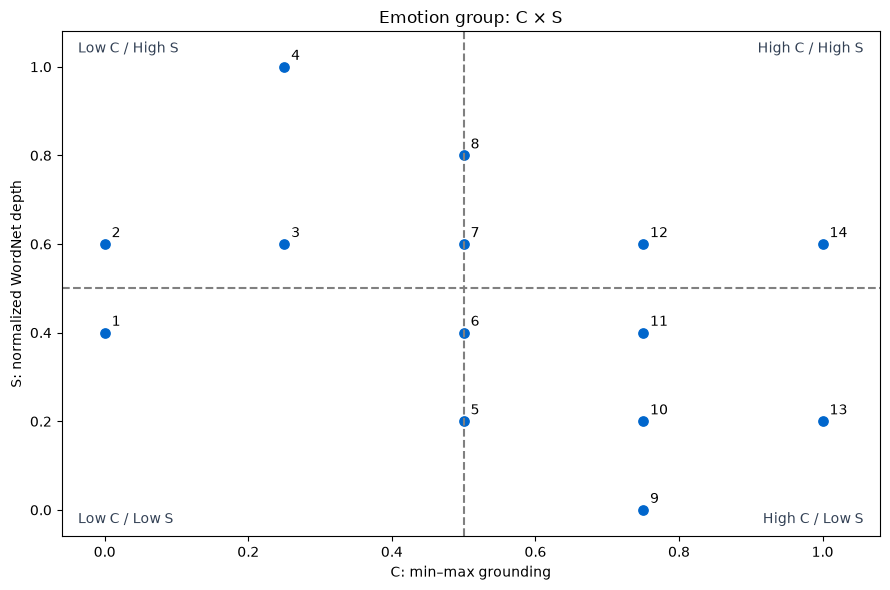

,Point,Concepts
0,1,flood
1,2,nausea
2,3,scar
3,4,warmth
4,5,mood
5,6,"disgust, anxiety, heaviness"
6,7,freeze
7,8,"resentment, sting"
8,9,feeling
9,10,sadness


In [11]:
# Number tied points and keep the word list next to the plot
fig, ax = plt.subplots(figsize=(9, 6))
point_key = []
for number, ((c, s), group) in enumerate(data.groupby(['C_norm', 'S_norm'], sort=True), start=1):
    ax.scatter(c, s, s=45, color='#0066CC')
    ax.annotate(str(number), (c, s), xytext=(5, 5), textcoords='offset points')
    point_key.append({'Point': number, 'Concepts': ', '.join(group['term'])})

ax.axvline(0.5, color='gray', linestyle='--')
ax.axhline(0.5, color='gray', linestyle='--')
quadrant_labels = [
    (0.02, 0.98, 'Low C / High S', 'left', 'top'),
    (0.98, 0.98, 'High C / High S', 'right', 'top'),
    (0.02, 0.02, 'Low C / Low S', 'left', 'bottom'),
    (0.98, 0.02, 'High C / Low S', 'right', 'bottom'),
]
for x, y, label, horizontal, vertical in quadrant_labels:
    ax.text(
        x,
        y,
        label,
        transform=ax.transAxes,
        ha=horizontal,
        va=vertical,
        fontsize=10,
        color='#334155',
    )
ax.set_xlabel('C: min–max grounding')
ax.set_ylabel('S: normalized WordNet depth')
ax.set_title('Emotion group: C × S')
ax.set_xlim(-0.06, 1.08)
ax.set_ylim(-0.06, 1.08)
plt.tight_layout()
plt.savefig('scatter.png', dpi=160)
plt.show()
display(pd.DataFrame(point_key))

## Task 3. Test sensitivity

$A = w(1-C) + (1-w)(1-S)$. Use the slider or call `simulator(w=0.5)` to change the weight.

In [12]:
def simulator(w=0.5):
    result = data[['term', 'C_norm', 'S_norm']].copy()
    result['A'] = abstractness(result['C_norm'], result['S_norm'], w)
    return result.sort_values('A', ascending=False).round(3)

In [13]:
try:
    from ipywidgets import FloatSlider, interact

    interact(simulator, w=FloatSlider(value=0.5, min=0, max=1, step=0.1))
except ImportError:
    display(simulator(w=0.5))

interactive(children=(FloatSlider(value=0.5, description='w', max=1.0), Output()), _dom_classes=('widget-inter…

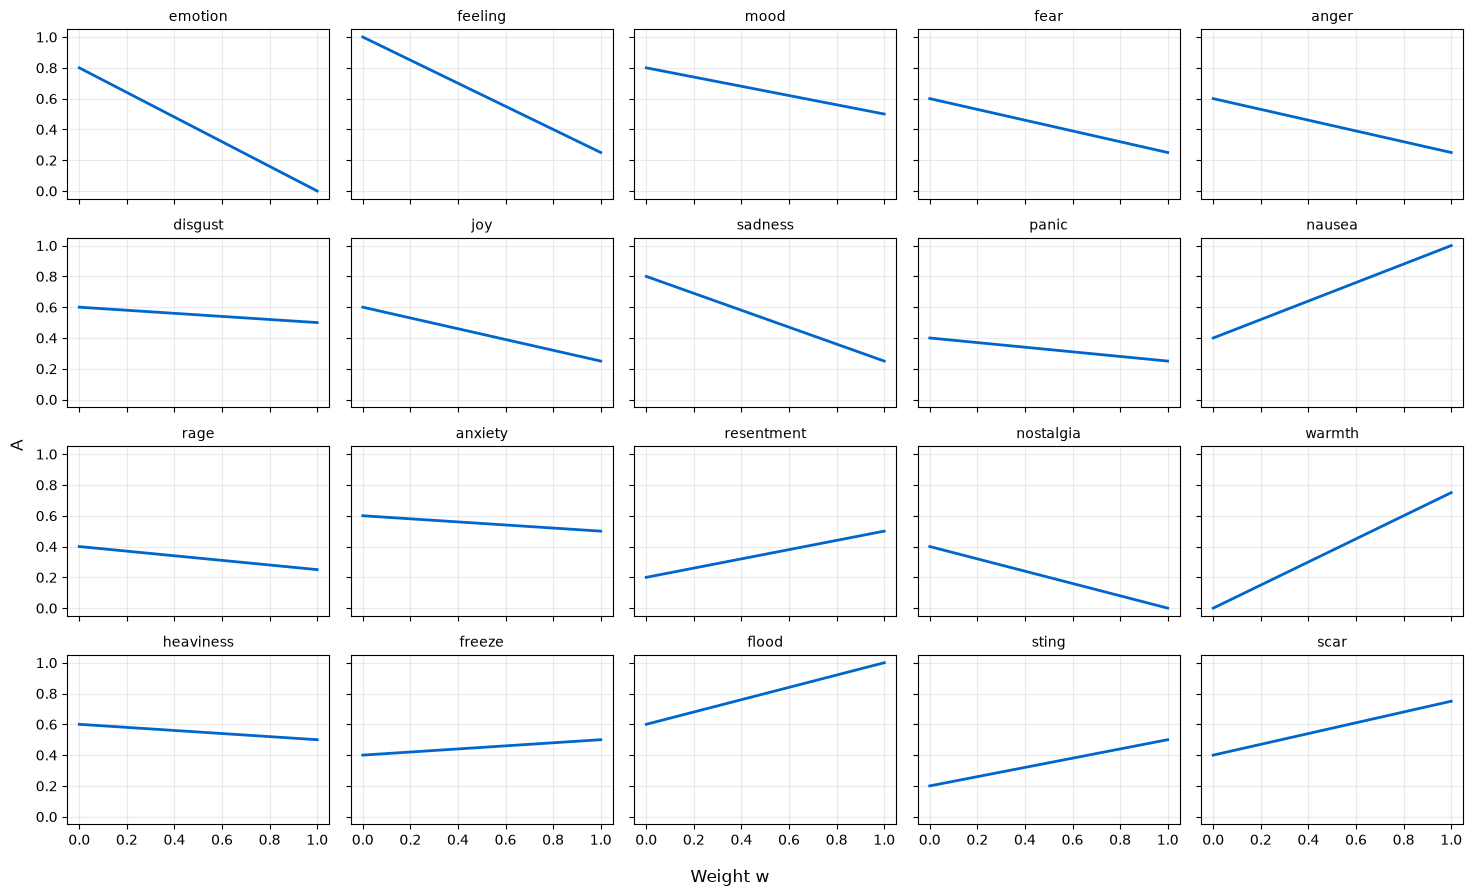

In [14]:
# Use separate panels so overlapping curves remain readable
weights = np.linspace(0, 1, 11)
fig, axes = plt.subplots(4, 5, figsize=(15, 9), sharex=True, sharey=True)

for ax, (_, row) in zip(axes.flat, data.iterrows()):
    scores = abstractness(row['C_norm'], row['S_norm'], weights)
    ax.plot(weights, scores, linewidth=2, color='#0066CC')
    ax.set_title(row['term'], fontsize=10)
    ax.grid(True, alpha=0.25)

fig.supxlabel('Weight w')
fig.supylabel('A')
plt.tight_layout()
plt.savefig('weight_sensitivity.png', dpi=160)
plt.show()

In [15]:
# A change in sign at the endpoints identifies a strict ranking reversal
crossings = {term: [] for term in data['term']}
for i in range(len(data)):
    for j in range(i + 1, len(data)):
        first = data.iloc[i]
        second = data.iloc[j]
        difference_start = second['S_norm'] - first['S_norm']
        difference_end = second['C_norm'] - first['C_norm']
        if difference_start * difference_end < -1e-12:
            crossings[first['term']].append(second['term'])
            crossings[second['term']].append(first['term'])

weight_results = data[['term', 'C_norm', 'S_norm']].copy()
weight_results['A_range_0_1'] = (data['C_norm'] - data['S_norm']).abs()
weight_results['A_range_02_08'] = 0.6 * weight_results['A_range_0_1']
weight_results['rank_crossings'] = data['term'].map(lambda term: ', '.join(crossings[term]))
weight_results['fragile'] = (
    (weight_results['A_range_0_1'] > 0.1 + 1e-12)
    | weight_results['rank_crossings'].ne('')
)

directions = np.select(
    [weight_results['C_norm'] > weight_results['S_norm'],
     weight_results['C_norm'] < weight_results['S_norm']],
    ['decreases', 'increases'],
    default='stays constant',
)
weight_results['explanation'] = [
    f"Increasing w shifts weight toward 1 - C, so A {direction} "
    f"by {row['A_range_0_1']:.3f} over w = 0 to 1 "
    f"(C = {row['C_norm']:.3f}, S = {row['S_norm']:.3f})."
    for (_, row), direction in zip(weight_results.iterrows(), directions, strict=True)
]
weight_results.to_csv('weight_sensitivity.csv', index=False)
weight_summary = weight_results[['term', 'A_range_0_1', 'A_range_02_08', 'fragile']].copy()
weight_summary['Direction and cause'] = np.select(
    [data['S_norm'] > data['C_norm'], data['C_norm'] > data['S_norm']],
    ['Rises because S > C', 'Falls because C > S'],
    default='Flat because C = S',
)
weight_summary['Rank reversals'] = weight_summary['term'].map(lambda term: len(crossings[term]))
display(
    weight_summary.rename(
        columns={
            'A_range_0_1': 'ΔA (0–1)',
            'A_range_02_08': 'ΔA (0.2–0.8)',
        }
    ).round(3)
)

,term,ΔA (0–1),ΔA (0.2–0.8),fragile,Direction and cause,Rank reversals
0,emotion,0.80,0.48,True,Falls because C > S,15
1,feeling,0.75,0.45,True,Falls because C > S,11
2,mood,0.30,0.18,True,Falls because C > S,5
3,fear,0.35,0.21,True,Falls because C > S,7
4,anger,0.35,0.21,True,Falls because C > S,7
5,disgust,0.10,0.06,True,Falls because C > S,6
6,joy,0.35,0.21,True,Falls because C > S,7
7,sadness,0.55,0.33,True,Falls because C > S,10
8,panic,0.15,0.09,True,Falls because C > S,4
9,nausea,0.60,0.36,True,Rises because S > C,10


Rank reversals and fragility use the full weight range from 0 to 1.

### Word-frequency check

OLS regresses raw grounding on log frequency. Baseline and residual grounding use the same min–max transformation. A separate rank-scaled comparison tests sensitivity to the normalization.

In [16]:
# The cached English frequencies were extracted with wordfreq==3.1.1.
assert (
    hashlib.sha256((data_path / 'word_frequency.csv').read_bytes()).hexdigest()
    == 'ac170ff97aa8167790aa1b8f58dcd89511bf135e38f358b006f654603146e88a'
)
frequency_source = pd.read_csv(data_path / 'word_frequency.csv')
assert frequency_source['term'].is_unique
assert set(data['term']) == set(frequency_source['term'])
frequency_check = data[['term', 'C_raw', 'C_norm', 'S_norm', 'A_0.5']].merge(
    frequency_source, on='term', how='left', validate='one_to_one'
)
assert frequency_check['zipf_frequency'].gt(0).all()
assert np.allclose(
    frequency_check['log10_frequency_per_million'],
    frequency_check['zipf_frequency'] - 3,
)

# If installed, verify the cache against the pinned package; neither path uses a network.
try:
    from importlib.metadata import version
    from wordfreq import zipf_frequency
except ImportError:
    print('Using the bundled wordfreq 3.1.1 frequency subset.')
else:
    assert version('wordfreq') == '3.1.1'
    reproduced = [zipf_frequency(term, 'en', wordlist='large') for term in frequency_check['term']]
    assert np.allclose(reproduced, frequency_check['zipf_frequency'], atol=1e-12, rtol=0)

In [17]:
logfreq = frequency_check['log10_frequency_per_million'].to_numpy()
c_raw = frequency_check['C_raw'].to_numpy()
design = np.column_stack([np.ones(len(logfreq)), logfreq])
intercept, slope = np.linalg.lstsq(design, c_raw, rcond=None)[0]
fitted = design @ np.array([intercept, slope])
residual = c_raw - fitted
frequency_check['C_residual'] = residual
frequency_check['C_adjusted_norm'] = normalize(residual, method='minmax').to_numpy()
frequency_check['A_adjusted'] = abstractness(
    frequency_check['C_adjusted_norm'], frequency_check['S_norm'], w=0.5
)
frequency_check['delta_A'] = frequency_check['A_adjusted'] - frequency_check['A_0.5']
rho_frequency = (
    frequency_check['C_raw'].rank().corr(frequency_check['log10_frequency_per_million'].rank())
)
variance = np.sum((c_raw - c_raw.mean()) ** 2)
frequency_r2 = 1 - np.sum(residual**2) / variance if variance > 0 else np.nan
print(f'Spearman rho(C_raw, log frequency): {rho_frequency:.3f}')
print(
    f'OLS C_raw = {intercept:.3f} + {slope:.3f} × log10 frequency per million; R² = {frequency_r2:.3f}'
)
print(f'Positive association exceeds the lecture diagnostic of 0.4: {rho_frequency > 0.4}')
display(
    frequency_check[
        [
            'term',
            'zipf_frequency',
            'C_raw',
            'C_norm',
            'C_residual',
            'C_adjusted_norm',
            'A_0.5',
            'A_adjusted',
            'delta_A',
        ]
    ].round(3)
)
rank_raw = normalize(c_raw, 'rank')
rank_adjusted = normalize(residual, 'rank')
frequency_check['delta_A_rank'] = abstractness(
    rank_adjusted, frequency_check['S_norm']
) - abstractness(rank_raw, frequency_check['S_norm'])
print('Maximum absolute change under min–max and rank scaling:')
print(frequency_check[['delta_A', 'delta_A_rank']].abs().max().round(3))
frequency_check.to_csv('frequency_check.csv', index=False)

,term,zipf_frequency,C_raw,C_norm,C_residual,C_adjusted_norm,A_0.5,A_adjusted,delta_A
0,emotion,4.19,1.143,1.00,0.240,0.929,0.400,0.435,0.035
1,feeling,5.13,1.000,0.75,0.023,0.584,0.625,0.708,0.083
2,mood,4.44,0.857,0.50,-0.066,0.443,0.650,0.679,0.029
3,fear,4.95,1.000,0.75,0.037,0.607,0.425,0.497,0.072
4,anger,4.42,1.000,0.75,0.079,0.673,0.425,0.464,0.039
5,disgust,3.61,0.857,0.50,-0.001,0.546,0.550,0.527,-0.023
6,joy,4.55,1.000,0.75,0.069,0.657,0.425,0.472,0.047
7,sadness,3.88,1.000,0.75,0.121,0.740,0.525,0.530,0.005
8,panic,4.26,1.000,0.75,0.091,0.693,0.325,0.354,0.029
9,nausea,3.54,0.571,0.00,-0.281,0.100,0.700,0.650,-0.050


### Binary C baseline

The binary baseline assigns high C when C ≥ 0.5. Within-group ranges show the information lost by this projection. These labels are derived from C, not independent concreteness ratings.

In [18]:
# A descriptive binary baseline derived from C, not an external concreteness norm.
binary_baseline = data[['term', 'C_norm', 'S_norm', 'A_0.5']].copy()
binary_baseline['binary_C'] = np.where(binary_baseline['C_norm'] >= 0.5, 'high C', 'low C')
binary_summary = binary_baseline.groupby('binary_C', sort=True).agg(
    n=('term', 'size'),
    C_min=('C_norm', 'min'),
    C_max=('C_norm', 'max'),
    S_min=('S_norm', 'min'),
    S_max=('S_norm', 'max'),
    A_min=('A_0.5', 'min'),
    A_max=('A_0.5', 'max'),
)
display(binary_summary.round(3))
binary_baseline.to_csv('binary_baseline.csv', index=False)

,n,C_min,C_max,S_min,S_max,A_min,A_max
binary_C,,,,,,,
high C,16,0.5,1.00,0.0,0.8,0.200,0.65
low C,4,0.0,0.25,0.4,1.0,0.375,0.80


### Alternative model choices

At w = 0.5, compare changes in C aggregation, S definition and normalization against the baseline.

In [19]:
baseline = data['A_0.5']
scenarios = {}
scenario_axes = {}

_, c_rank = compute_C(data, normalization='rank')
scenarios['C_rank'] = abstractness(c_rank, data['S_norm'])
scenario_axes['C_rank'] = (c_rank, data['S_norm'])

for rule in ['sum', 'max']:
    _, c = compute_C(data, rule=rule)
    scenarios[f'C_{rule}'] = abstractness(c, data['S_norm'])
    scenario_axes[f'C_{rule}'] = (c, data['S_norm'])

_, c_without = compute_C(data, include_proprioception=False)
scenarios['C_without_proprioception'] = abstractness(c_without, data['S_norm'])
scenario_axes['C_without_proprioception'] = (c_without, data['S_norm'])

for rule in ['depth_max', 'descendants', 'log_descendants']:
    _, s = compute_S(data, rule=rule)
    scenarios[f'S_{rule}'] = abstractness(data['C_norm'], s)
    scenario_axes[f'S_{rule}'] = (data['C_norm'], s)

_, s_rank = compute_S(data, normalization='rank')
scenarios['S_rank'] = abstractness(data['C_norm'], s_rank)
scenario_axes['S_rank'] = (data['C_norm'], s_rank)
scenarios['C_frequency_adjusted'] = frequency_check['A_adjusted'].set_axis(data.index)
scenario_axes['C_frequency_adjusted'] = (frequency_check['C_adjusted_norm'], data['S_norm'])

In [20]:
# Keep failed alternatives visible instead of treating them as zero changes
alternative_scores = pd.DataFrame(scenarios)
valid = [column for column in alternative_scores if alternative_scores[column].notna().all()]
invalid = [column for column in alternative_scores if column not in valid]
if invalid:
    print('Undefined alternatives:', invalid)

changes = alternative_scores.subtract(baseline, axis=0).abs()
changes.insert(0, 'term', data['term'])
changes['max_delta'] = changes[valid].max(axis=1)
changes['largest_alternative'] = changes[valid].idxmax(axis=1)
changes['fragile'] = changes['max_delta'] > 0.1 + 1e-12
changes['poorly_represented'] = changes['max_delta'] > 0.2 + 1e-12
largest_branch = data.loc[data['descendants'].idxmax()]
alternative_reasons = {
    'C_rank': 'Rank scaling changes distances between tied feature sums.',
    'C_sum': 'Sum and mean have the same order and ties, so normalized C is unchanged.',
    'C_max': 'The maximum drops the other channels and may be constant across the inventory.',
    'C_without_proprioception': 'Removing a generated channel changes feature sums and their range.',
    'S_depth_max': 'Longest depth instead of shortest depth tests alternative root paths.',
    'S_descendants': f"Descendant count replaces depth; {largest_branch['term']} has the largest branch ({int(largest_branch['descendants'])} descendants).",
    'S_log_descendants': 'Log descendant count compresses differences between large taxonomic branches.',
    'S_rank': 'Rank scaling preserves depth order but changes distances between specificity scores.',
    'C_frequency_adjusted': 'OLS residuals remove the linear association between raw C and word frequency.',
}
changes['explanation'] = changes['largest_alternative'].map(alternative_reasons)
changes.to_csv('sensitivity_alternatives.csv', index=False)
display(changes[['term', 'max_delta', 'largest_alternative']].round(3))

,term,max_delta,largest_alternative
0,emotion,0.255,S_descendants
1,feeling,0.083,C_frequency_adjusted
2,mood,0.389,S_descendants
3,fear,0.273,S_descendants
4,anger,0.280,S_descendants
5,disgust,0.297,S_descendants
6,joy,0.290,S_descendants
7,sadness,0.362,S_descendants
8,panic,0.199,S_descendants
9,nausea,0.193,S_descendants


In [21]:
comparison_rows = []
for name, scores in scenarios.items():
    if name not in valid:
        continue
    ranks = scores.rank().corr(baseline.rank())
    comparison_rows.append(
        {
            'Alternative': name,
            'Max absolute change': (scores - baseline).abs().max(),
            'Changes above 0.1': ((scores - baseline).abs() > 0.1 + 1e-12).sum(),
            'Rank correlation with baseline': ranks,
        }
    )
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv('model_comparison.csv', index=False)
display(comparison.round(3))

quadrant_rows = []
for name, (c, s) in {'baseline': (data['C_norm'], data['S_norm']), **scenario_axes}.items():
    counts = pd.Series([quadrant(x, y) for x, y in zip(c, s)]).value_counts()
    quadrant_rows.append({'Alternative': name, **counts.to_dict()})
quadrant_results = pd.DataFrame(quadrant_rows).fillna(0)
quadrant_results.to_csv('quadrant_sensitivity.csv', index=False)
display(quadrant_results)

,Alternative,Max absolute change,Changes above 0.1,Rank correlation with baseline
0,C_rank,0.069,0,0.974
1,C_sum,0.000,0,1.000
2,C_without_proprioception,0.250,2,0.959
3,S_depth_max,0.000,0,1.000
4,S_descendants,0.389,16,0.772
5,S_log_descendants,0.210,10,0.781
6,S_rank,0.061,0,0.950
7,C_frequency_adjusted,0.087,0,0.932


,Alternative,boundary,high C / low S,high C / high S,low C / high S,low C / low S,missing
0,baseline,7.0,6.0,3.0,3.0,1.0,0.0
1,C_rank,0.0,6.0,3.0,6.0,5.0,0.0
2,C_sum,7.0,6.0,3.0,3.0,1.0,0.0
3,C_max,0.0,0.0,0.0,0.0,0.0,20.0
4,C_without_proprioception,5.0,6.0,3.0,4.0,2.0,0.0
5,S_depth_max,7.0,6.0,3.0,3.0,1.0,0.0
6,S_descendants,7.0,1.0,8.0,4.0,0.0,0.0
7,S_log_descendants,7.0,4.0,5.0,4.0,0.0,0.0
8,S_rank,7.0,6.0,3.0,3.0,1.0,0.0
9,C_frequency_adjusted,0.0,8.0,5.0,4.0,3.0,0.0


In [22]:
# Show how one large branch affects min–max descendant specificity
_, descendant_s = compute_S(data, rule='descendants')
_, log_descendant_s = compute_S(data, rule='log_descendants')
descendant_check = data[['term', 'descendants', 'S_norm']].copy()
descendant_check['S_descendants'] = descendant_s
descendant_check['S_log_descendants'] = log_descendant_s
display(descendant_check.nlargest(3, 'descendants').round(4))

normalization_changes = changes[['term', 'C_rank', 'S_rank']]
normalization_changes.to_csv('normalization_sensitivity.csv', index=False)

stable = ~weight_results['fragile'] & ~changes['fragile']
print('Stable under all tested checks:', ', '.join(data.loc[stable, 'term']) or 'none')
data.to_csv('results.csv', index=False)

,term,descendants,S_norm,S_descendants,S_log_descendants
1,feeling,445,0.0,0.0000,0.0000
0,emotion,129,0.2,0.7101,0.2021
7,sadness,34,0.2,0.9236,0.4172


### Uncertain socialness scores

The four provisional ratings use selected senses. Enumerate all 81 assignments under the primary min–max rule and count midpoint observations separately.

In [23]:
missing_social = data.index[~sourced_social].tolist()
social_score_runs = []
social_coverage = []
coverage_counts = []
for scores in product([0, 1, 2], repeat=len(missing_social)):
    variant = data.copy()
    variant.loc[missing_social, 'social'] = scores
    _, c_variant = compute_C(variant)
    social_score_runs.append(abstractness(c_variant, data['S_norm']).to_numpy())
    counts = pd.Series([quadrant(c, s) for c, s in zip(c_variant, data['S_norm'])]).value_counts()
    coverage_counts.append(dict(counts))
    social_coverage.append(
        all(
            counts.get(q, 0) >= 3
            for q in ['high C / high S', 'high C / low S', 'low C / high S', 'low C / low S']
        )
    )
social_score_runs = np.asarray(social_score_runs)
social_sensitivity = data[['term', 'social', 'social_provenance', 'A_0.5']].copy()
social_sensitivity['A_min'] = social_score_runs.min(axis=0)
social_sensitivity['A_max'] = social_score_runs.max(axis=0)
social_sensitivity['max_delta_A'] = np.abs(social_score_runs - data['A_0.5'].to_numpy()).max(axis=0)
social_sensitivity.to_csv('social_sensitivity.csv', index=False)
print(
    f'Coverage remains at least 3 per quadrant in {sum(social_coverage)}/{len(social_coverage)} combinations.'
)
display(social_sensitivity[['term', 'A_min', 'A_max', 'max_delta_A']].round(3))
print('Range of quadrant counts over 81 assignments')
display(pd.DataFrame(coverage_counts).fillna(0).agg(['min', 'max']))

,term,A_min,A_max,max_delta_A
0,emotion,0.400,0.400,0.00
1,feeling,0.625,0.625,0.00
2,mood,0.650,0.650,0.00
3,fear,0.425,0.425,0.00
4,anger,0.425,0.425,0.00
5,disgust,0.550,0.550,0.00
6,joy,0.425,0.425,0.00
7,sadness,0.525,0.525,0.00
8,panic,0.325,0.325,0.00
9,nausea,0.700,0.700,0.00


,boundary,high C / low S,high C / high S,low C / high S,low C / low S
min,5,6,3,2,0.0
max,9,7,5,3,1.0


### Sceptic’s note

Norms are word-level, while WordNet identifies senses. `Feeling` ratings may include touch; `warmth`, `heaviness`, `freeze`, `flood`, `sting` and `scar` may mix literal and emotional readings. `Freeze` uses a broad noun sense for an interruption of movement, not the more specific fear-response verb. Generated features and normalization choices are tested separately.

### Normalization, sense choice and rank crossings

In [24]:
z = (data.C_raw - data.C_raw.mean()) / data.C_raw.std(ddof=0)
# Compare orderings at equal coefficients. A with a standardized axis is unbounded.
a_z = abstractness(z, data.S_norm)
six = [f for f in features if f != 'social']
six_c = normalize(data[six].mean(axis=1))
display(
    pd.DataFrame(
        {
            'term': data.term,
            'C_z': z,
            'A_z': a_z,
            'A_without_social': abstractness(six_c, data.S_norm),
        }
    ).round(3)
)
print(
    'Z-score comparison, Spearman correlation of A rankings:', a_z.rank().corr(data['A_0.5'].rank())
)
# Selected-sense counterfactual: vary the ambiguous haptic bin only.
trials = []
for term in ['feeling', 'freeze', 'warmth']:
    for score in [0, 1, 2]:
        trial = data.copy()
        mask = trial.term.eq(term)
        trial.loc[mask, 'tactile'] = score
        _, c_trial = compute_C(trial)
        trials.append([term, score, abstractness(c_trial, data.S_norm)[mask].item()])
display(pd.DataFrame(trials, columns=['term', 'assumed tactile bin', 'A at equal weights']))

,term,C_z,A_z,A_without_social
0,emotion,1.606,0.097,0.40
1,feeling,0.688,0.656,0.50
2,mood,-0.229,1.015,0.65
3,fear,0.688,0.456,0.30
4,anger,0.688,0.456,0.55
5,disgust,-0.229,0.915,0.55
6,joy,0.688,0.456,0.55
7,sadness,0.688,0.556,0.65
8,panic,0.688,0.356,0.20
9,nausea,-2.065,1.732,0.70


,term,assumed tactile bin,A at equal weights
0,feeling,0,0.875
1,feeling,1,0.750
2,feeling,2,0.625
3,freeze,0,0.700
4,freeze,1,0.575
5,freeze,2,0.450
6,warmth,0,0.500
7,warmth,1,0.500
8,warmth,2,0.375


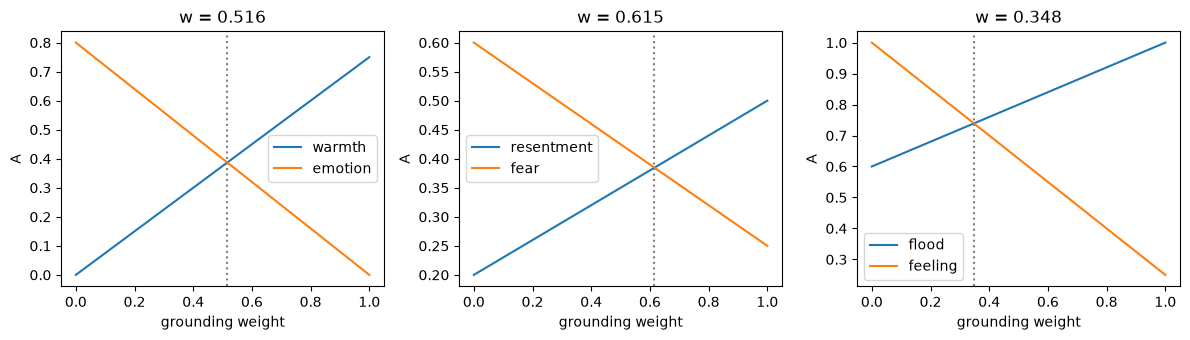

In [25]:
pairs = [('warmth', 'emotion'), ('resentment', 'fear'), ('flood', 'feeling')]
indexed = data.set_index('term')
fig, axes = plt.subplots(1, len(pairs), figsize=(12, 3.5))
for ax, (left, right) in zip(axes, pairs):
    l, r = indexed.loc[left], indexed.loc[right]
    d_s, d_c = l.S_norm - r.S_norm, l.C_norm - r.C_norm
    crossing = d_s / (d_s - d_c)
    assert 0 < crossing < 1
    for term, row in [(left, l), (right, r)]:
        ax.plot(weights, abstractness(row.C_norm, row.S_norm, weights), label=term)
    ax.axvline(crossing, linestyle=':', color='gray')
    ax.set(title=f'w = {crossing:.3f}', xlabel='grounding weight', ylabel='A')
    ax.legend()
fig.tight_layout()
fig.savefig('rank_crossings.png', dpi=150)
plt.show()

## Task 4. Test the held-out prediction

Predict the continuous Diveica socialness rating using Lancaster means. Each fold excludes one word before centering and scaling. Ridge minimizes the sum of squared errors plus the squared coefficient norm (alpha = 1), with an unpenalized intercept. MAE is in socialness rating units. See the [ridge objective](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).

In [26]:
observed = data.loc[sourced_social].reset_index(drop=True)
target = observed.source_social.to_numpy()
columns = [
    'source_visual',
    'source_auditory',
    'source_tactile',
    'source_motor',
    'source_interoceptive',
]
predictions = []
for i, term in enumerate(observed.term):
    train = np.arange(len(observed)) != i
    mean_y = target[train].mean()
    record = {'term': term, 'observed': target[i], 'training_mean': mean_y}
    for name, channels in [('four_channels', columns[:4]), ('with_interoception', columns)]:
        x = observed[channels].to_numpy()
        mu, sd = x[train].mean(axis=0), x[train].std(axis=0)
        scaled = (x - mu) / np.where(sd > 0, sd, 1)
        xt = scaled[train]
        beta = np.linalg.solve(xt.T @ xt + np.eye(len(channels)), xt.T @ (target[train] - mean_y))
        record[name] = mean_y + scaled[i] @ beta
    predictions.append(record)
held_out = pd.DataFrame(predictions)
held_out.to_csv('held_out_predictions.csv', index=False)
mae = held_out.iloc[:, 2:].sub(held_out.observed, axis=0).abs().mean()
display(mae.rename('held-out MAE').round(4))
print('Relative error reduction:', round(1 - mae.with_interoception / mae.four_channels, 4))

training_mean         0.6588
four_channels         0.7254
with_interoception    0.7713
Name: held-out MAE, dtype: float64

### Results

[Interpretation](interpretation.md)